<a href="https://colab.research.google.com/github/zmgriffin/Data201-labs/blob/main/homework/Week8_Regularization_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Zachary Griffin

Data 201 Fall 2026

Week 8: Regularization HW


In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

## Part 1: Experiment with Alpha:

Using the same training and test sets from the lab, fit three Lasso models with:  
alpha_values = [0.1, 10, 100].

Report Training and test RMSE, and number of nonzero coefficients.

In [3]:
# load data
hitters = load_data('Hitters')
print('Original shape:', hitters.shape)
display(hitters.head())
# Check for NAs
print('Missing values:')
print(hitters.isna().sum().sort_values())


Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
Salary       59
dtype: int64


In [4]:
# remove the salary NAs
hitters = hitters.dropna(subset=['Salary']).copy()

# separate features and target
X = hitters.drop(columns='Salary')
y = hitters['Salary'] # reported in thousands

# numeric columns and category columns
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(cat_cols) #confirm this worked

#train-test splitsplit
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=27)

print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


In [5]:

# preprossing
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), num_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)
            ])

alpha_values = [0.1, 10, 100]
rows = []

for a in alpha_values:
  pipe = Pipeline([
      ('preprocess', make_preprocessor()),
      ('model', Lasso(max_iter=30000).set_params(alpha=a))
          ])
  pipe.fit(X_train, y_train)

        # get coeff
  coefs = pipe.named_steps['model'].coef_

        #each time the loop runs, we add one dictionary to the list "rows".
  rows.append({
      'alpha': a,
      'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)), #count nonzero coefficients
      'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))),
      'Test RMSE': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test))),
        })
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))




,alpha,Nonzero coefficients,Training RMSE,Test RMSE
0,0.1,18,302.80,319.64
1,10.0,11,323.08,330.66
2,100.0,4,360.01,383.97


1. As α increases, what happens to the number of retained predictors?

As alpha increases, fewer of predictors are kept.

2. Does a smaller number of predictors always lead to a lower test RMSE?

No,  lowering predictors often increases the training error, and in this cases also increased the testing error.

## Part 2: Visualize and interpret

Create a graph showing α versus Test RMSE for the three models.


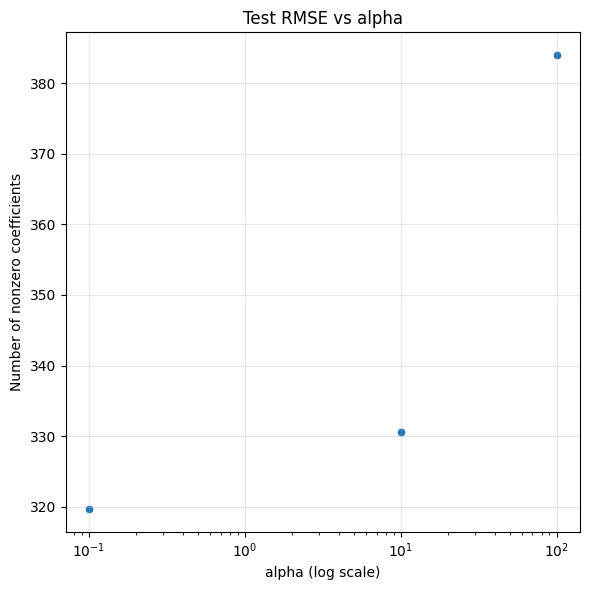

In [6]:
fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(alpha_table,
                x = 'alpha',
                y = 'Test RMSE'
                )
ax.set_title(f'Test RMSE vs alpha')
ax.set_xscale("log")
ax.set_xlabel('alpha (log scale)')
ax.set_ylabel('Number of nonzero coefficients')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Part 3- Model interpretation (3 points)
Using your results from Part 1:
1. Identify two predictors that Lasso sets to zero at α = 100.
2. Does setting their coefficients to zero prove that these predictors have no relationship
with salary? Explain.
3. If two models have very similar test RMSE but one uses fewer predictors, which would
you prefer? Explain your answer in terms of interpretability and predictive performance.



In [9]:

pipe2 = Pipeline([
      ('preprocess', make_preprocessor()),
      ('model', Lasso(max_iter=30000).set_params(alpha=100))
          ])
pipe2.fit(X_train, y_train)


feature_names = pipe2.named_steps['preprocess'].get_feature_names_out()

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'coeff': pipe2.named_steps['model'].coef_,
})

display(coef_table.round(2))


,Feature,coeff
0,num__AtBat,0.00
1,num__Hits,46.99
2,num__HmRun,0.00
3,num__Runs,0.00
4,num__RBI,0.00
5,num__Walks,25.33
6,num__Years,0.00
7,num__CAtBat,0.00
8,num__CHits,0.00
9,num__CHmRun,0.00


1. Predictors that alpha=100 set at zero included number of Career Hits, and number of Runs.
2. These coefficients being zero does not mean that these variables have no relationship with salary, merely that they are highly correlated with another variable.
3. If two models have similar test RMSE values, generally choose the one with fewer variables, as it is easier for users to interpret.

## Part 4 - Choosing the Right Regression Model (4 points)
For each scenario, choose Ridge (L2), Lasso (L1), Ordinary Linear Regression, or Not Sure.
Explain your choice in 2-3 sentences, considering the number of predictors, model complexity,
interpretability, and potential overfitting. - - - -
1. Scenario A: A researcher has data from 80 patients with 200 medical measurements. The
goal is to identify a small number of measurements that may be useful for predicting
disease severity.

*Lasso, to reduce from 200 predictors to a smaller number of more useful. The small sample size could be a problem for overfitting.*

2. Scenario B: A company wants to predict employee salaries using 40 predictors. Many
predictors are strongly correlated, and the company believes most contain useful
information. Keeping all predictors is not a concern.

*Ridge. If we want to keep all the predictors, lasso is not the best option. Ridge will compensate for the correlated variables to make a simpler model than OLR.*

3. Scenario C: A researcher has 10,000 observations and only three predictors. The
relationship appears approximately linear, and the researcher wants a simple model that is
easy to interpret.

*OLR is the simplest model. No need to worry about getting rid of predictors with Lasso here.*

4. Scenario D: A company has 500 observations and 25 predictors. It is unclear how many
predictors are useful or how strongly they are correlated. The company wants the most
accurate predictions possible.

*Not sure. Would have to try them all and check RMSE and R^2 values.*